In [1]:
from preprocessing import load_splits, build_preprocessor, rmse, FEATURES, TARGET
from sklearn.tree import DecisionTreeRegressor
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
train_split, val_split = load_splits()

preprocessor = build_preprocessor()

X_train = preprocessor.fit_transform(train_split[FEATURES])
X_val = preprocessor.transform(val_split[FEATURES])

y_train = train_split[TARGET]
y_val = val_split[TARGET]

print("Training observations:", len(y_train))
print("Validation observations:", len(y_val))

Training observations: 5918
Validation observations: 1480


In [12]:
decision_tree = DecisionTreeRegressor(random_state=42)

decision_tree.fit(X_train, y_train)

train_predictions = decision_tree.predict(X_train)
val_predictions = decision_tree.predict(X_val)

train_rmse = rmse(y_train, train_predictions)
val_rmse = rmse(y_val, val_predictions)

print("Decision Tree Training RMSE:", round(train_rmse, 2))
print("Decision Tree Validation RMSE:", round(val_rmse, 2))

Decision Tree Training RMSE: 39.35
Decision Tree Validation RMSE: 559.31


In [13]:
tuned_tree = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=5,
    random_state=42
)

tuned_tree.fit(X_train, y_train)

tuned_train_pred = tuned_tree.predict(X_train)
tuned_val_pred = tuned_tree.predict(X_val)

tuned_train_rmse = rmse(y_train, tuned_train_pred)
tuned_val_rmse = rmse(y_val, tuned_val_pred)

print("Constrained Tree Training RMSE:", round(tuned_train_rmse, 2))
print("Constrained Tree Validation RMSE:", round(tuned_val_rmse, 2))

Constrained Tree Training RMSE: 381.57
Constrained Tree Validation RMSE: 516.24


## Decision Tree Model Evaluation

The initial Decision Tree model achieved a training RMSE of $39.35 and a validation RMSE of $559.31. The large difference between these values indicates substantial overfitting, meaning the model learned the training data too closely and struggled to generalize to unseen observations.

To address this issue, I trained a constrained Decision Tree using `max_depth=10` and `min_samples_leaf=5`.

The constrained model achieved a training RMSE of $381.57 and a validation RMSE of $516.24.

Although the training RMSE increased, the validation RMSE decreased by $43.07 (approximately 7.7%). This suggests that limiting the tree's complexity improved its generalization performance.

The constrained Decision Tree also achieved a lower validation RMSE than the Linear Regression baseline of $550.04.

These results demonstrate the importance of controlling model complexity and evaluating performance on unseen data rather than relying only on training performance.

In [8]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameters to test
param_grid = {
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 5, 10]
}

# Create the Grid Search
grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)

# Find the best hyperparameters using training data only
grid_search.fit(X_train, y_train)

# Display the results
print("Best Hyperparameters:", grid_search.best_params_)
print("Best Cross-Validation RMSE:", round(-grid_search.best_score_, 2))

Best Hyperparameters: {'max_depth': 15, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best Cross-Validation RMSE: 491.8


In [11]:
best_tree = grid_search.best_estimator_

best_train_pred = best_tree.predict(X_train)
best_val_pred = best_tree.predict(X_val)

best_train_rmse = rmse(y_train, best_train_pred)
best_val_rmse = rmse(y_val, best_val_pred)

print("GridSearch Decision Tree Training RMSE:", round(best_train_rmse, 2))
print("GridSearch Decision Tree Validation RMSE:", round(best_val_rmse, 2))

GridSearch Decision Tree Training RMSE: 391.18
GridSearch Decision Tree Validation RMSE: 511.11


In [10]:
comparison = pd.DataFrame({
    "Model": [
        "Original Decision Tree",
        "Constrained Decision Tree",
        "GridSearch Decision Tree"
    ],
    "Training RMSE": [
        train_rmse,
        tuned_train_rmse,
        best_train_rmse
    ],
    "Validation RMSE": [
        val_rmse,
        tuned_val_rmse,
        best_val_rmse
    ]
})

comparison = comparison.sort_values("Validation RMSE")

comparison.round(2)

,Model,Training RMSE,Validation RMSE
2,GridSearch Decision Tree,391.18,511.11
1,Constrained Decision Tree,381.57,516.24
0,Original Decision Tree,39.35,559.31


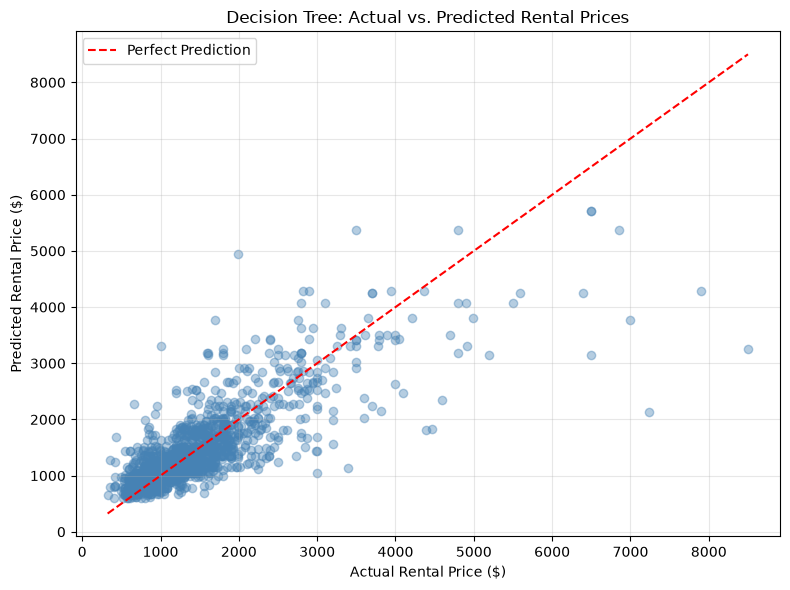

In [15]:
# Visualize actual vs. predicted rental prices
plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    best_val_pred,
    alpha=0.4,
    color="steelblue"
)

# Draw a reference line for perfect predictions
limits = [
    min(y_val.min(), best_val_pred.min()),
    max(y_val.max(), best_val_pred.max())
]

plt.plot(
    limits,
    limits,
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Rental Price ($)")
plt.ylabel("Predicted Rental Price ($)")
plt.title("Decision Tree: Actual vs. Predicted Rental Prices")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Final Decision Tree Results and Interpretation

Three Decision Tree models were evaluated using the team's shared training and validation datasets.

The original Decision Tree showed substantial overfitting, achieving a training RMSE of 39.95 and a validation RMSE of 559.31

To reduce overfitting, a constrained Decision Tree was developed using a maximum depth of 10 and a minimum of 5 samples per leaf. This improved the validation RMSE to $516.24.

GridSearchCV was then used with 5-fold cross-validation to systematically evaluate 36 hyperparameter combinations using only the training data.

The best hyperparameters were:
- Maximum depth: 15
- Minimum samples per leaf: 10
- Minimum samples required to split: 2

The final tuned Decision Tree achieved:
- Training RMSE: $391.18
- cross validation RMSE: 491.80
- Validation RMSE: $511.11

The tuned model achieved the lowest validation RMSE among the three Decision Tree models evaluated, improving performance by $48.20 compared with the original model.

The tuned Decision Tree also outperformed the team's Linear Regression baseline, which achieved a validation RMSE of $550.04.

Although the tuned model still has a gap between training and validation performance, its improved validation RMSE suggests better generalization than the original unrestricted Decision Tree.

The tuned Decision Tree is therefore the strongest Decision Tree candidate evaluated in this notebook. However, the team's final model should be selected after comparing its performance with Random Forest and Gradient Boosting.